In [1]:
!pip install -q insightface scikit-learn matplotlib pandas opencv-python

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_lfw_people

from insightface.app import FaceAnalysis

In [3]:
lfw = fetch_lfw_people(
    min_faces_per_person=20,
    resize=0.5,
    color=True
)

print("Images:", lfw.images.shape)
print("People:", len(lfw.target_names))

Images: (3023, 62, 47, 3)
People: 62


In [4]:
for i, name in enumerate(lfw.target_names):

    print(
        i,
        name,
        "images:",
        np.sum(lfw.target == i)
    )

0 Alejandro Toledo images: 39
1 Alvaro Uribe images: 35
2 Amelie Mauresmo images: 21
3 Andre Agassi images: 36
4 Angelina Jolie images: 20
5 Ariel Sharon images: 77
6 Arnold Schwarzenegger images: 42
7 Atal Bihari Vajpayee images: 24
8 Bill Clinton images: 29
9 Carlos Menem images: 21
10 Colin Powell images: 236
11 David Beckham images: 31
12 Donald Rumsfeld images: 121
13 George Robertson images: 22
14 George W Bush images: 530
15 Gerhard Schroeder images: 109
16 Gloria Macapagal Arroyo images: 44
17 Gray Davis images: 26
18 Guillermo Coria images: 30
19 Hamid Karzai images: 22
20 Hans Blix images: 39
21 Hugo Chavez images: 71
22 Igor Ivanov images: 20
23 Jack Straw images: 28
24 Jacques Chirac images: 52
25 Jean Chretien images: 55
26 Jennifer Aniston images: 21
27 Jennifer Capriati images: 42
28 Jennifer Lopez images: 21
29 Jeremy Greenstock images: 24
30 Jiang Zemin images: 20
31 John Ashcroft images: 53
32 John Negroponte images: 31
33 Jose Maria Aznar images: 23
34 Juan Carlos Fe

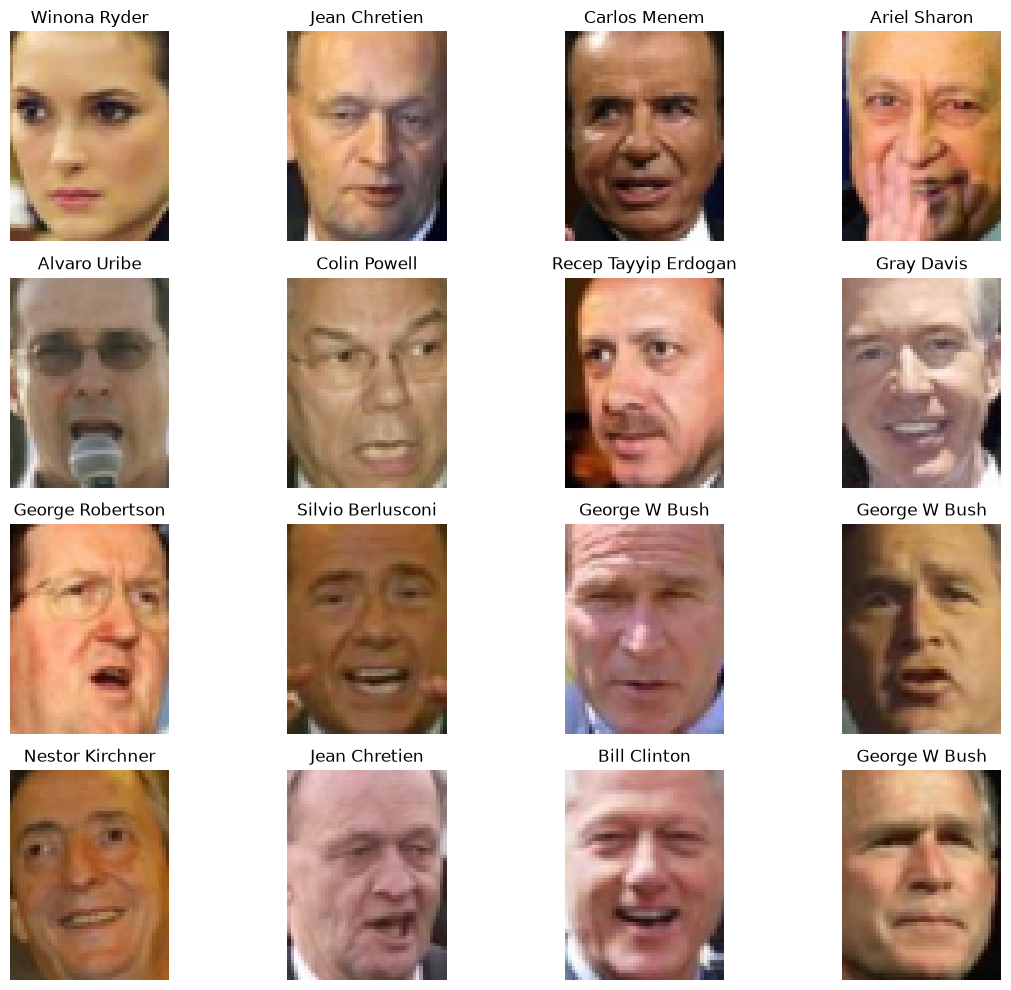

In [5]:
plt.figure(figsize=(12, 10))

for i in range(16):

    plt.subplot(4, 4, i + 1)

    plt.imshow(lfw.images[i])

    plt.title(
        lfw.target_names[
            lfw.target[i]
        ]
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
app_s = FaceAnalysis(
    name="buffalo_s",
    providers=["CPUExecutionProvider"]
)

app_s.prepare(ctx_id=-1)

print("Buffalo-S loaded.")

Buffalo-S loaded.


In [7]:
app_l = FaceAnalysis(
    name="buffalo_l",
    providers=["CPUExecutionProvider"]
)

app_l.prepare(ctx_id=-1)

print("Buffalo-L loaded.")

download_path: C:\Users\akars/.insightface\models\buffalo_l


100%|██████████| 281857/281857 [05:24<00:00, 867.68KB/s] 


Buffalo-L loaded.


In [8]:
def prepare_image(image):

    image = np.asarray(image)

    if image.dtype != np.uint8:

        image = (
            image * 255
        ).clip(
            0,
            255
        ).astype(np.uint8)

    # RGB → BGR
    image = image[:, :, ::-1]

    return image

In [9]:
def get_embedding(app, image):

    image = prepare_image(image)

    faces = app.get(image)

    if len(faces) == 0:
        return None

    # Select largest face
    face = max(
        faces,
        key=lambda x: (
            x.bbox[2] - x.bbox[0]
        ) * (
            x.bbox[3] - x.bbox[1]
        )
    )

    embedding = face.embedding

    embedding = embedding / np.linalg.norm(
        embedding
    )

    return embedding

In [10]:
test_embedding = get_embedding(
    app_s,
    lfw.images[0]
)

print(
    "Embedding shape:",
    None if test_embedding is None
    else test_embedding.shape
)

C:\Users\akars\Capstone\test\YOLO11\myvenv\Lib\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


Embedding shape: (512,)


In [11]:
NUM_AUTHORIZED = 5

authorized_ids = list(
    range(NUM_AUTHORIZED)
)

for person_id in authorized_ids:

    print(
        person_id,
        lfw.target_names[person_id]
    )

0 Alejandro Toledo
1 Alvaro Uribe
2 Amelie Mauresmo
3 Andre Agassi
4 Angelina Jolie


In [12]:
enrollment_embeddings = {}

for person_id in authorized_ids:

    indices = np.where(
        lfw.target == person_id
    )[0]

    embeddings = []

    for index in indices[:5]:

        embedding = get_embedding(
            app_s,
            lfw.images[index]
        )

        if embedding is not None:
            embeddings.append(embedding)

    if embeddings:

        mean_embedding = np.mean(
            embeddings,
            axis=0
        )

        mean_embedding /= np.linalg.norm(
            mean_embedding
        )

        enrollment_embeddings[
            person_id
        ] = mean_embedding

print(
    "Enrollment identities:",
    len(enrollment_embeddings)
)

Enrollment identities: 5


In [25]:
from pathlib import Path
import pickle

RESULTS_DIR = Path("Capstone/AI_Intruder_Capstone/models")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

ENROLLMENT_FILE = RESULTS_DIR / "enrollment_db_buffalo_s.pkl"

with open(ENROLLMENT_FILE, "wb") as f:
    pickle.dump(enrollment_embeddings, f)

print("Enrollment database saved to:")
print(ENROLLMENT_FILE)
print("Number of enrolled people:", len(enrollment_embeddings))

Enrollment database saved to:
Capstone\AI_Intruder_Capstone\models\enrollment_db_buffalo_s.pkl
Number of enrolled people: 5


In [13]:
def cosine_similarity(a, b):

    return np.dot(a, b) / (
        np.linalg.norm(a) *
        np.linalg.norm(b)
    )

In [14]:
def recognize(
    embedding,
    database,
    threshold=0.5
):

    best_person = None
    best_score = -1

    for person_id, stored_embedding in database.items():

        score = cosine_similarity(
            embedding,
            stored_embedding
        )

        if score > best_score:

            best_score = score
            best_person = person_id

    if best_score >= threshold:

        return best_person, best_score

    return None, best_score

In [15]:
results = []

for person_id in authorized_ids:

    indices = np.where(
        lfw.target == person_id
    )[0]

    # Skip enrollment images
    test_indices = indices[5:]

    for index in test_indices:

        embedding = get_embedding(
            app_s,
            lfw.images[index]
        )

        if embedding is None:
            continue

        predicted_id, score = recognize(
            embedding,
            enrollment_embeddings,
            threshold=0.5
        )

        results.append({
            "actual": person_id,
            "predicted": predicted_id,
            "score": score
        })

recognition_df = pd.DataFrame(results)

recognition_df.head()

,actual,predicted,score
0,0,0,0.673700
1,0,0,0.744137
2,0,0,0.762610
3,0,0,0.634872
4,0,0,0.726286


In [16]:
recognition_df["correct"] = (
    recognition_df["actual"] ==
    recognition_df["predicted"]
)

accuracy = recognition_df["correct"].mean()

print(
    f"Recognition accuracy: {accuracy:.4f}"
)

Recognition accuracy: 1.0000


In [17]:
intruder_ids = list(
    range(
        NUM_AUTHORIZED,
        NUM_AUTHORIZED + 10
    )
)

print("Intruder IDs:")

for person_id in intruder_ids:

    print(
        person_id,
        lfw.target_names[person_id]
    )

Intruder IDs:
5 Ariel Sharon
6 Arnold Schwarzenegger
7 Atal Bihari Vajpayee
8 Bill Clinton
9 Carlos Menem
10 Colin Powell
11 David Beckham
12 Donald Rumsfeld
13 George Robertson
14 George W Bush


In [18]:
intruder_results = []

for person_id in intruder_ids:

    indices = np.where(
        lfw.target == person_id
    )[0]

    for index in indices:

        embedding = get_embedding(
            app_s,
            lfw.images[index]
        )

        if embedding is None:
            continue

        predicted_id, score = recognize(
            embedding,
            enrollment_embeddings,
            threshold=0.5
        )

        intruder_results.append({
            "actual": person_id,
            "predicted": predicted_id,
            "score": score,
            "is_intruder": True
        })

intruder_df = pd.DataFrame(
    intruder_results
)

intruder_df.head()

C:\Users\akars\Capstone\test\YOLO11\myvenv\Lib\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


,actual,predicted,score,is_intruder
0,5,None,0.118365,True
1,5,None,0.082198,True
2,5,None,0.115442,True
3,5,None,0.158838,True
4,5,None,0.100375,True


In [19]:
false_acceptances = (
    intruder_df["predicted"].notna()
)

FAR = false_acceptances.mean()

print(
    f"False Acceptance Rate: {FAR:.4f}"
)

False Acceptance Rate: 0.0000


In [27]:
enrollment_db_l = {}

for person_id in authorized_ids:
    embeddings = []

    for image_idx in person_images[person_id]:
        embedding = get_embedding(app_l, lfw.images[image_idx])

        if embedding is not None:
            embeddings.append(embedding)

    if embeddings:
        mean_embedding = np.mean(embeddings, axis=0)
        mean_embedding /= np.linalg.norm(mean_embedding)

        enrollment_db_l[person_id] = mean_embedding

NameError: name 'person_images' is not defined

In [30]:
enrollment_db_l = {}

for person_id in authorized_ids:

    indices = np.where(
        lfw.target == person_id
    )[0]

    embeddings = []

    for index in indices[:5]:

        embedding = get_embedding(
            app_l,
            lfw.images[index]
        )

        if embedding is not None:
            embeddings.append(embedding)

    if embeddings:

        mean_embedding = np.mean(
            embeddings,
            axis=0
        )

        mean_embedding /= np.linalg.norm(
            mean_embedding
        )

        enrollment_db_l[
            person_id
        ] = mean_embedding

print(
    "Enrollment identities:",
    len(enrollment_embeddings)
)

Enrollment identities: 5


In [31]:
ENROLLMENT_FILE_L = RESULTS_DIR / "enrollment_db_buffalo_l.pkl"

with open(ENROLLMENT_FILE_L, "wb") as f:
    pickle.dump(enrollment_db_l, f)

print("Buffalo-L enrollment database saved.")
print("Number of enrolled people:", len(enrollment_db_l))

Buffalo-L enrollment database saved.
Number of enrolled people: 5
